# Water Quality Regression with Index Patches + Temporal/Weather Features

This notebook trains a **multimodal PyTorch regression model** using:
- Spatial inputs from `river_patches_with_indices` (**derived indices only**: NDVI, NDMI, water mask)
- Tabular context features (temporal + weather + scene metadata)
- Targets from `DATA/water_quality_training_dataset.csv`

It uses a group-aware **train/validation/test** split to better reflect real-world generalization across locations.


In [1]:
import os
import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from torchvision.models import resnet18


In [2]:
# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


In [3]:
# Paths and configuration
ROOT = Path(".")
CSV_PATH = ROOT / "DATA" / "water_quality_training_dataset.csv"
META_PATH = ROOT / "river_patches" / "metadata.json"
IDX_DIR = ROOT / "river_patches_with_indices"

# We use only derived index channels from 7-band files:
# band 5: water_mask, band 6: NDVI, band 7: NDMI
INDEX_BANDS = [6, 7, 5]  # [NDVI, NDMI, water_mask]

TARGET_COLS = [
    "Total Alkalinity",
    "Electrical Conductance",
    "Dissolved Reactive Phosphorus",
]

TEST_SIZE = 0.2
VAL_SIZE = 0.15
BATCH_SIZE = 16

# Ablation switch: set True to include cyclic/time-index datetime features.
# Default False because these features were hurting generalization in this split.
USE_DATETIME_FEATURES = False

# In notebooks on macOS/Windows, multiprocessing workers can fail to pickle
# Dataset classes defined in __main__. Keep workers at 0 here.
NUM_WORKERS = 0
MAX_EPOCHS = 40
PATIENCE = 6
LR = 5e-4
WEIGHT_DECAY = 5e-4
IMG_SIZE = 224
TAB_DROPOUT = 0.2
HEAD_DROPOUT = 0.3


In [10]:
def load_and_prepare_dataframe(csv_path: Path, meta_path: Path, idx_dir: Path, use_datetime_features: bool = False) -> pd.DataFrame:
    labels = pd.read_csv(csv_path).reset_index().rename(columns={"index": "dataset_index"})

    with open(meta_path, "r") as f:
        meta = json.load(f)
    meta_df = pd.json_normalize(meta, sep="_")

    needed_meta = [
        "dataset_index", "patch_id", "file", "lat", "lon", "target_date",
        "target_date_iso", "actual_date", "days_difference", "cloud_cover",
        "download_status", "scalar_features_rainfall_7day_mm",
        "scalar_features_temperature_celsius",
    ]
    missing_cols = [c for c in needed_meta if c not in meta_df.columns]
    if missing_cols:
        raise ValueError(f"Missing metadata columns: {missing_cols}")

    meta_df = meta_df[meta_df["download_status"].isin(["downloaded", "exists"])].copy()

    meta_df["idx_tif"] = meta_df["patch_id"].apply(lambda x: idx_dir / f"patch_{int(x)}.tif")
    meta_df = meta_df[meta_df["idx_tif"].apply(lambda p: Path(p).exists())].copy()

    df = meta_df.merge(labels, on="dataset_index", how="inner", suffixes=("_meta", ""))

    # # Keep only examples where satellite date is within one month of actual date
    # df["days_difference"] = pd.to_numeric(df["days_difference"], errors="coerce")
    # df = df[df["days_difference"].abs() <= 160].copy()

    if "Sample Date" in df.columns:
        df["sample_date"] = pd.to_datetime(df["Sample Date"], format="%d-%m-%Y", errors="coerce")
    else:
        df["sample_date"] = pd.to_datetime(df["target_date_iso"], errors="coerce")

    # Temporal encodings (seasonal + long-term trend)
    df["day_of_year"] = df["sample_date"].dt.dayofyear
    df["month"] = df["sample_date"].dt.month
    df["iso_week"] = df["sample_date"].dt.isocalendar().week.astype(float)
    df["day_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
    df["day_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12.0)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12.0)
    df["week_sin"] = np.sin(2 * np.pi * df["iso_week"] / 52.0)
    df["week_cos"] = np.cos(2 * np.pi * df["iso_week"] / 52.0)
    df["time_index_days"] = (df["sample_date"] - df["sample_date"].min()).dt.days

    for t in TARGET_COLS:
        if t not in df.columns:
            raise ValueError(f"Target column missing: {t}")

    tab_cols = [
        "scalar_features_rainfall_7day_mm",
        "scalar_features_temperature_celsius",
        "days_difference",
        "cloud_cover",
    ]

    datetime_cols = [
        "day_sin",
        "day_cos",
        "month_sin",
        "month_cos",
        "week_sin",
        "week_cos",
        "time_index_days",
    ]
    if use_datetime_features:
        tab_cols.extend(datetime_cols)

    for col in tab_cols + TARGET_COLS:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(subset=TARGET_COLS).copy()
    for col in tab_cols:
        df[col] = df[col].fillna(df[col].median())

    df["group_id"] = df["lat"].round(4).astype(str) + "_" + df["lon"].round(4).astype(str)

    return df, tab_cols


df, TAB_COLS = load_and_prepare_dataframe(
    CSV_PATH,
    META_PATH,
    IDX_DIR,
    use_datetime_features=USE_DATETIME_FEATURES,
)

print("Total usable samples:", len(df))
print("Unique stations/groups:", df["group_id"].nunique())
print("Targets:", TARGET_COLS)
print("Using datetime features:", USE_DATETIME_FEATURES)
print("Tabular features:", TAB_COLS)

df.head(3)


Total usable samples: 5664
Unique stations/groups: 159
Targets: ['Total Alkalinity', 'Electrical Conductance', 'Dissolved Reactive Phosphorus']
Using datetime features: False
Tabular features: ['scalar_features_rainfall_7day_mm', 'scalar_features_temperature_celsius', 'days_difference', 'cloud_cover']


,patch_id,dataset_index,file,lat,lon,target_date,target_date_iso,actual_date,days_difference,cloud_cover,...,month,iso_week,day_sin,day_cos,month_sin,month_cos,week_sin,week_cos,time_index_days,group_id
0,0,0,river_patches/patch_0.tif,-28.760833,17.730278,02-01-2011,2011-01-02,2010-04-05,271.645054,0.0,...,1,52.0,0.034398,0.999408,0.5,0.866025,6.432491e-16,1.000000,0,-28.7608_17.7303
1,1,1,river_patches/patch_1.tif,-26.861111,28.884722,03-01-2011,2011-01-03,2009-04-17,625.677930,0.0,...,1,1.0,0.051584,0.998669,0.5,0.866025,1.205367e-01,0.992709,1,-26.8611_28.8847
2,2,2,river_patches/patch_2.tif,-26.450000,28.085833,03-01-2011,2011-01-03,2009-03-23,650.674269,0.0,...,1,1.0,0.051584,0.998669,0.5,0.866025,1.205367e-01,0.992709,1,-26.45_28.0858


In [11]:
# Train/validation/test split (all group-aware)
# Keep test untouched during training; use validation for early stopping.
gss_outer = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
trainval_idx, test_idx = next(gss_outer.split(df, groups=df["group_id"]))

trainval_df = df.iloc[trainval_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

# Validation as a fraction of full dataset (not of trainval)
val_relative = VAL_SIZE / (1.0 - TEST_SIZE)
gss_inner = GroupShuffleSplit(n_splits=1, test_size=val_relative, random_state=SEED)
train_idx, val_idx = next(gss_inner.split(trainval_df, groups=trainval_df["group_id"]))

train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

print(f"Train samples: {len(train_df)}")
print(f"Val samples:   {len(val_df)}")
print(f"Test samples:  {len(test_df)}")
print(f"Train groups: {train_df['group_id'].nunique()}")
print(f"Val groups:   {val_df['group_id'].nunique()}")
print(f"Test groups:  {test_df['group_id'].nunique()}")


Train samples: 3883
Val samples:   928
Test samples:  853
Train groups: 103
Val groups:   24
Test groups:  32


In [12]:
# Scale tabular inputs and targets using train statistics only
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_tab = x_scaler.fit_transform(train_df[TAB_COLS].values)
X_val_tab = x_scaler.transform(val_df[TAB_COLS].values)
X_test_tab = x_scaler.transform(test_df[TAB_COLS].values)

Y_train = y_scaler.fit_transform(train_df[TARGET_COLS].values)
Y_val = y_scaler.transform(val_df[TARGET_COLS].values)
Y_test = y_scaler.transform(test_df[TARGET_COLS].values)

print("Tab scaler mean:", np.round(x_scaler.mean_, 3))
print("Target scaler mean:", np.round(y_scaler.mean_, 3))


Tab scaler mean: [ 10.475  17.412 332.945   6.263]
Target scaler mean: [123.919 498.803  43.564]


In [13]:
class WaterQualityDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, tab_scaled: np.ndarray, y_scaled: np.ndarray, img_size: int = 224, augment: bool = False):
        self.frame = frame.reset_index(drop=True)
        self.tab = tab_scaled.astype(np.float32)
        self.y = y_scaled.astype(np.float32)
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.frame)

    def _read_indices(self, tif_path: Path):
        with rasterio.open(tif_path) as src:
            arr = src.read(INDEX_BANDS).astype(np.float32)  # [3, H, W] -> NDVI, NDMI, water_mask

        arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
        arr[0] = np.clip(arr[0], -1.0, 1.0)  # NDVI
        arr[1] = np.clip(arr[1], -1.0, 1.0)  # NDMI
        arr[2] = np.clip(arr[2], 0.0, 1.0)   # water mask

        x = torch.from_numpy(arr)
        x = F.interpolate(x.unsqueeze(0), size=(self.img_size, self.img_size), mode="bilinear", align_corners=False).squeeze(0)

        if self.augment:
            if torch.rand(1).item() < 0.5:
                x = torch.flip(x, dims=[2])
            if torch.rand(1).item() < 0.5:
                x = torch.flip(x, dims=[1])
            if torch.rand(1).item() < 0.5:
                k = int(torch.randint(0, 4, (1,)).item())
                x = torch.rot90(x, k=k, dims=[1, 2])
            if torch.rand(1).item() < 0.3:
                noise = torch.randn_like(x) * 0.02
                x = x + noise

        x[0] = torch.clamp(x[0], -1.0, 1.0)
        x[1] = torch.clamp(x[1], -1.0, 1.0)
        x[2] = torch.clamp(x[2], 0.0, 1.0)

        return x

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        x_img = self._read_indices(Path(row["idx_tif"]))
        x_tab = torch.from_numpy(self.tab[idx])
        y = torch.from_numpy(self.y[idx])
        return x_img, x_tab, y


In [14]:
train_ds = WaterQualityDataset(train_df, X_train_tab, Y_train, img_size=IMG_SIZE, augment=True)
val_ds = WaterQualityDataset(val_df, X_val_tab, Y_val, img_size=IMG_SIZE, augment=False)
test_ds = WaterQualityDataset(test_df, X_test_tab, Y_test, img_size=IMG_SIZE, augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

xb_img, xb_tab, yb = next(iter(train_loader))
print("Image batch:", xb_img.shape)
print("Tab batch:", xb_tab.shape)
print("Target batch:", yb.shape)


Image batch: torch.Size([16, 3, 224, 224])
Tab batch: torch.Size([16, 4])
Target batch: torch.Size([16, 3])


In [15]:
class MultiModalResNetRegressor(nn.Module):
    def __init__(self, tab_dim: int, out_dim: int):
        super().__init__()

        self.cnn = resnet18(weights=None)
        self.cnn.fc = nn.Identity()  # output: 512

        self.img_proj = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(HEAD_DROPOUT),
        )

        self.tab_branch = nn.Sequential(
            nn.Linear(tab_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.Dropout(TAB_DROPOUT),
            nn.Linear(64, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(TAB_DROPOUT),
        )

        self.head = nn.Sequential(
            nn.Linear(256 + 64, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(HEAD_DROPOUT),
            nn.Linear(128, out_dim),
        )

    def forward(self, x_img, x_tab):
        z_img = self.img_proj(self.cnn(x_img))
        z_tab = self.tab_branch(x_tab)
        z = torch.cat([z_img, z_tab], dim=1)
        return self.head(z)


model = MultiModalResNetRegressor(tab_dim=len(TAB_COLS), out_dim=len(TARGET_COLS)).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
criterion = nn.SmoothL1Loss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

print(model.__class__.__name__)


MultiModalResNetRegressor


In [16]:
from tqdm.notebook import tqdm

In [17]:
def run_epoch(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)

    total_loss = 0.0
    n = 0

    for x_img, x_tab, y in tqdm(loader, desc="Epoch", total=len(loader)):
        x_img = x_img.to(device, non_blocking=True)
        x_tab = x_tab.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with torch.set_grad_enabled(is_train):
            pred = model(x_img, x_tab)
            loss = criterion(pred, y)

            if is_train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

        bs = x_img.size(0)
        total_loss += loss.item() * bs
        n += bs

    return total_loss / max(n, 1)


In [18]:
history = {"train_loss": [], "val_loss": []}
best_val = float("inf")
best_state = None
bad_epochs = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = run_epoch(model, train_loader, optimizer=optimizer)
    val_loss = run_epoch(model, val_loader, optimizer=None)

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch {epoch:02d}/{MAX_EPOCHS} | train={train_loss:.4f} | val={val_loss:.4f}")

    if val_loss < best_val:
        best_val = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1

    if bad_epochs >= PATIENCE:
        print(f"Early stopping after {epoch} epochs.")
        break

if best_state is not None:
    model.load_state_dict(best_state)

print("Best validation loss:", round(best_val, 5))


Epoch:   0%|          | 0/243 [00:00<?, ?it/s]

Epoch:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 01/40 | train=0.3956 | val=0.2948


Epoch:   0%|          | 0/243 [00:00<?, ?it/s]

Epoch:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 02/40 | train=0.3810 | val=0.2594


... (10 outputs left out)

Epoch:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 06/40 | train=0.3016 | val=0.2858


Epoch:   0%|          | 0/243 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [19]:
if best_state is not None:
    model.load_state_dict(best_state)

In [20]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, trues = [], []

    for x_img, x_tab, y in loader:
        x_img = x_img.to(device, non_blocking=True)
        x_tab = x_tab.to(device, non_blocking=True)

        out = model(x_img, x_tab).cpu().numpy()
        preds.append(out)
        trues.append(y.numpy())

    return np.vstack(preds), np.vstack(trues)

pred_scaled, true_scaled = predict(model, test_loader)

pred = y_scaler.inverse_transform(pred_scaled)
true = y_scaler.inverse_transform(true_scaled)

metrics = []
for i, t in enumerate(TARGET_COLS):
    mae = mean_absolute_error(true[:, i], pred[:, i])
    rmse = math.sqrt(mean_squared_error(true[:, i], pred[:, i]))
    r2 = r2_score(true[:, i], pred[:, i])
    metrics.append({"target": t, "MAE": mae, "RMSE": rmse, "R2": r2})

metrics_df = pd.DataFrame(metrics)
metrics_df


,target,MAE,RMSE,R2
0,Total Alkalinity,53.447163,64.623020,0.170954
1,Electrical Conductance,236.877960,326.627045,0.068277
2,Dissolved Reactive Phosphorus,30.779747,43.131322,0.090091


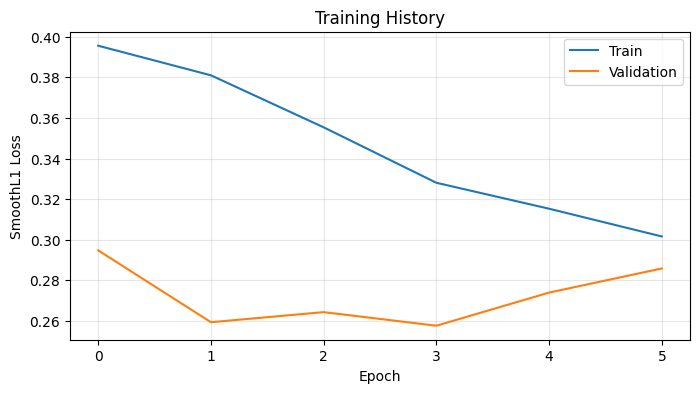

In [21]:
plt.figure(figsize=(8, 4))
plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("SmoothL1 Loss")
plt.title("Training History")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


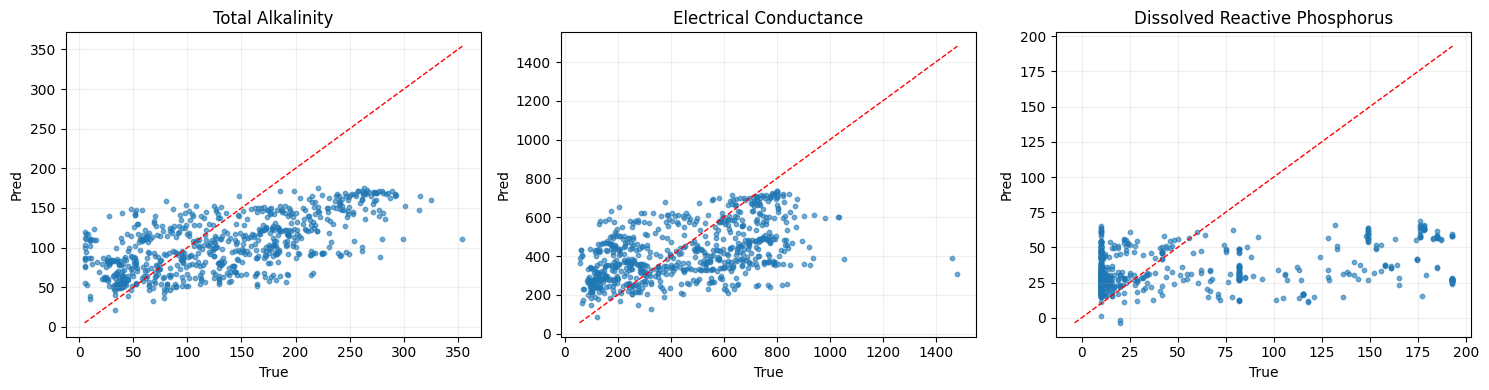

In [42]:
fig, axes = plt.subplots(1, len(TARGET_COLS), figsize=(5 * len(TARGET_COLS), 4))
if len(TARGET_COLS) == 1:
    axes = [axes]

for i, t in enumerate(TARGET_COLS):
    ax = axes[i]
    ax.scatter(true[:, i], pred[:, i], s=10, alpha=0.6)
    mn = min(true[:, i].min(), pred[:, i].min())
    mx = max(true[:, i].max(), pred[:, i].max())
    ax.plot([mn, mx], [mn, mx], "r--", linewidth=1)
    ax.set_title(t)
    ax.set_xlabel("True")
    ax.set_ylabel("Pred")
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()


In [43]:
# Save model artifacts for reuse
artifacts_dir = ROOT / "model_artifacts"
artifacts_dir.mkdir(exist_ok=True)

torch.save(model.state_dict(), artifacts_dir / "multimodal_resnet18_water_quality.pt")

import pickle
with open(artifacts_dir / "x_scaler.pkl", "wb") as f:
    pickle.dump(x_scaler, f)
with open(artifacts_dir / "y_scaler.pkl", "wb") as f:
    pickle.dump(y_scaler, f)

print("Saved model + scalers to", artifacts_dir)


Saved model + scalers to model_artifacts
